*Mathematical Foundations of Robotics · Chapter 2 — Spatial Descriptions and Transformations*

# 2.2 Mappings, Composition of Rotations and Operators

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/02-spatial-descriptions-and-transformations/2.2-mappings-and-operators.ipynb)

A rotation matrix is not only a *description* of a frame. The same matrix can **re-express** a point in another
frame (a *mapping*) and can **move** a vector within one frame (an *operator*). This notebook develops both uses,
derives the chain rule for composing rotations, and settles the question that causes more errors than any
other in introductory robotics: *when does a new rotation multiply on the left, and when on the right?*

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §2.3–2.5 |
| **Parallel reading** | Lynch & Park §3.2.1 (uses of rotation matrices) · Spong et al. Ch. 2 (rotational transformations; composition of rotations) · Siciliano et al. §2.2–2.3 |
| **Lectures** | [Prof. G. C. Nandi, Lecture 7 — Basics of rotational transformation](https://www.youtube.com/watch?v=588iwEM-Dto) · [Prof. G. C. Nandi, Lecture 15 — Spatial transformation explained in a simple way](https://www.youtube.com/watch?v=CJdCTyDpX4U) · [ThatsEngineering — Spatial descriptions — worked example](https://www.youtube.com/watch?v=r244ADkuexk) · [Modern Robotics 3.2.1 Rotation matrices (part 2)](https://www.youtube.com/watch?v=6KIPusOv5fA) |
| **Prerequisites** | [2.1 Positions, Orientations and Frames](2.1-positions-orientations-and-frames.ipynb) |
| **Study time** | about 2½ hours |

## Learning objectives

1. Map the coordinates of a point between translated, rotated and general frames: ${}^{A}P = {}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$.
2. Compose rotations with the chain rule ${}^{A}_{C}R = {}^{A}_{B}R\,{}^{B}_{C}R$ and check expressions by index cancellation.
3. State and justify the **multiplication-order rule**: rotations about *current* axes post-multiply; rotations about *fixed* axes pre-multiply.
4. Distinguish a **mapping** (the point stays, the frame changes) from an **operator** (the frame stays, the vector moves).
5. Use the skew-symmetric matrix $[\boldsymbol\omega]_\times$ to write cross products as matrix products.
6. Verify mappings and compositions against the poses computed by MuJoCo for a chain of nested bodies.

## Contents

1. [Mappings: changing the frame of description](#1.-Mappings:-changing-the-frame-of-description)
2. [Composing rotations: the chain rule](#2.-Composing-rotations:-the-chain-rule)
3. [Fixed axes versus current axes](#3.-Fixed-axes-versus-current-axes)
4. [Rotations do not commute](#4.-Rotations-do-not-commute)
5. [Operators: rotating and translating vectors](#5.-Operators:-rotating-and-translating-vectors)
6. [Three interpretations of a rotation matrix](#6.-Three-interpretations-of-a-rotation-matrix)
7. [Skew-symmetric matrices and the cross product](#7.-Skew-symmetric-matrices-and-the-cross-product)
8. [Mappings and compositions in MuJoCo](#8.-Mappings-and-compositions-in-MuJoCo)
9. [Worked examples](#9.-Worked-examples)
10. [Summary, common mistakes and exercises](#10.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit.transforms import rotx, roty, rotz, skew, is_rotation

## 1. Mappings: changing the frame of description

A **mapping** re-expresses *the same* point in a different frame. Nothing moves: only the numbers that describe
the point change. We treat three cases of increasing generality.

**Translated frames.** If $\{B\}$ has the same orientation as $\{A\}$ and its origin is at ${}^{A}P_{BORG}$, the
arrow from the origin of $\{A\}$ to $P$ is the sum of the arrow to the origin of $\{B\}$ and the arrow from there
to $P$. Because both frames have parallel axes, the components may be added directly:

$$
{}^{A}P = {}^{B}P + {}^{A}P_{BORG}.
$$

Vectors may be added only when they are expressed in frames of the **same orientation**; this is the reason the
next case is needed.

**Rotated frames.** If $\{B\}$ shares its origin with $\{A\}$ but is rotated, write
${}^{B}P = (p_x, p_y, p_z)$, which means $P = p_x\hat X_B + p_y\hat Y_B + p_z\hat Z_B$. Expressing each axis of
$\{B\}$ in $\{A\}$ gives

$$
{}^{A}P = p_x\,{}^{A}\hat X_B + p_y\,{}^{A}\hat Y_B + p_z\,{}^{A}\hat Z_B
= \begin{bmatrix}{}^{A}\hat X_B & {}^{A}\hat Y_B & {}^{A}\hat Z_B\end{bmatrix}{}^{B}P
= {}^{A}_{B}R\;{}^{B}P .
$$

**General frames.** If $\{B\}$ is both rotated and translated, first rotate the description into a frame
parallel to $\{A\}$ and then add the offset of the origin:

> **The general mapping (Craig eq. 2.18).**
> $$ {}^{A}P = {}^{A}_{B}R\;{}^{B}P + {}^{A}P_{BORG}. $$

The leading superscripts and subscripts make the formula self-checking: ${}^{A}_{B}R$ "cancels" the leading
$B$ of ${}^{B}P$ to leave something in $\{A\}$, which may then be added to ${}^{A}P_{BORG}$. The figure illustrates
the general mapping in the plane (rotation about $\hat Z$, which points out of the page).

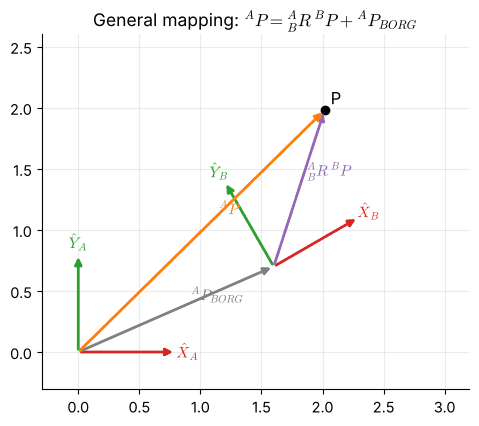

^B P = [1.  0.9]   ->  ^A P = [2.016  1.9794]


In [2]:
th, p_borg, P_B = deg(30), np.array([1.6, 0.7]), np.array([1.0, 0.9])
R2 = rotz(th)[:2, :2]
P_A = R2 @ P_B + p_borg

fig, ax = plt.subplots(figsize=(6.2, 4.6))
draw_frame_2d(ax, 0.0, name="A", length=0.8)
draw_frame_2d(ax, th, origin=p_borg, name="B", length=0.8)
draw_vector_2d(ax, [0, 0], p_borg, color="grey", label=r"${}^{A}P_{BORG}$")
draw_vector_2d(ax, p_borg, R2 @ P_B, color="#9467bd", label=r"${}^{A}_{B}R\,{}^{B}P$")
draw_vector_2d(ax, [0, 0], P_A, color="#ff7f0e", label=r"${}^{A}P$")
ax.plot(*P_A, "ko"); ax.text(P_A[0] + 0.05, P_A[1] + 0.05, "P", fontsize=12)
ax.set_xlim(-0.3, 3.2); ax.set_ylim(-0.3, 2.6); ax.set_aspect("equal"); ax.grid(alpha=0.25)
ax.set_title(r"General mapping: ${}^{A}P = {}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$")
plt.show()
print("^B P =", P_B, "  ->  ^A P =", P_A.round(4))

## 2. Composing rotations: the chain rule

Suppose the orientation of $\{C\}$ is known relative to $\{B\}$, and that of $\{B\}$ relative to $\{A\}$. Mapping
a point twice gives ${}^{A}P = {}^{A}_{B}R\,{}^{B}P = {}^{A}_{B}R\,\big({}^{B}_{C}R\,{}^{C}P\big)$. Since this holds
for every point,

$$
{}^{A}_{C}R = {}^{A}_{B}R\;{}^{B}_{C}R .
$$

The rule extends to any number of frames, ${}^{0}_{n}R = {}^{0}_{1}R\,{}^{1}_{2}R\cdots{}^{n-1}_{\;\;n}R$, and is the
core of forward kinematics (Chapter 3): the orientation of a robot's last link is the product of its
link-to-link rotations. The indices behave like cancelling fractions; if two adjacent indices do not match, the
product is meaningless.

## 3. Fixed axes versus current axes

A frame is often built from several elementary rotations — "rotate $30^\circ$ about $X$, then $45^\circ$ about
$Z$". Whether each new rotation multiplies on the right or on the left depends on **which axes** it is about.

**About the current (moving, body) axes.** Let $\{B\}$ have orientation $R$ and rotate it by $R_{\text{step}}$
about one of *its own* axes, producing $\{B'\}$. In $\{B\}$'s own coordinates this step is just
$R_{\text{step}}$; that is, ${}^{B}_{B'}R = R_{\text{step}}$. By the chain rule,
${}^{A}_{B'}R = {}^{A}_{B}R\;{}^{B}_{B'}R = R\,R_{\text{step}}$: **post-multiply**.

**About the fixed (world, reference) axes.** Now the step is defined in $\{A\}$'s coordinates. It acts as an
*operator* on each of the three axis vectors of $\{B\}$ written in $\{A\}$, i.e. on each column of $R$, so the
new orientation is $R_{\text{step}}\,R$: **pre-multiply**.

> **The multiplication-order rule.**
> * Rotation about a **current** (moving) axis ⇒ **post-multiply**: $R \leftarrow R\,R_{\text{step}}$.
> * Rotation about a **fixed** (world) axis ⇒ **pre-multiply**: $R \leftarrow R_{\text{step}}\,R$.
>
> Consequently a single product $R_1R_2R_3$ has two equally valid readings: *left to right* as rotations about
> current axes ($R_1$ first), or *right to left* as rotations about fixed axes ($R_3$ first).

The animation below performs "$90^\circ$ about $X$, then $90^\circ$ about $Z$" both ways. In the left panel the
second rotation is about the **new** $Z$ axis of the body; in the right panel it is about the **world** $Z$ axis.
The black dashed line marks the axis being turned about at each instant. The two final orientations differ.

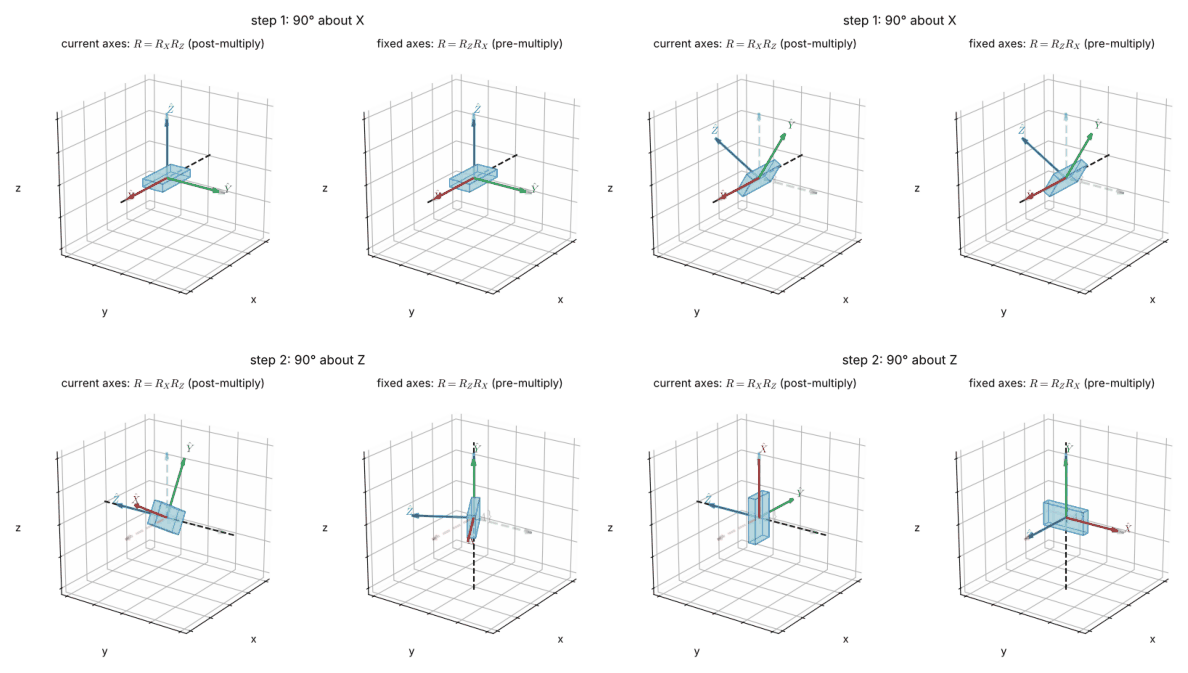

current axes  R_X(90) R_Z(90) =
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]]
fixed axes    R_Z(90) R_X(90) =
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [3]:
def two_step(s, frame):
    """Orientation after progress s in [0, 2]: 90° about X, then 90° about Z (current or fixed)."""
    a, b = deg(90) * np.clip(s, 0, 1), deg(90) * np.clip(s - 1, 0, 1)
    return rotx(a) @ rotz(b) if frame == "current" else rotz(b) @ rotx(a)

fig = plt.figure(figsize=(10, 4.8))
axes = [fig.add_subplot(1, 2, k + 1, projection="3d") for k in range(2)]

def update(s):
    for ax, frame in zip(axes, ("current", "fixed")):
        ax.cla()
        R = two_step(s, frame)
        rule = r"$R = R_X R_Z$ (post-multiply)" if frame == "current" else r"$R = R_Z R_X$ (pre-multiply)"
        new_axes3d(ax, lim=1.1, ticks=False, title=f"{frame} axes: {rule}")
        draw_frame(ax, np.eye(3), name="A", alpha=0.25, ls="--", label_axes=False)
        draw_frame(ax, R, length=0.9)
        draw_box(ax, np.block([[R, np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.12))
        if s <= 1:
            k = np.array([1.0, 0, 0])                                       # first step: X (same both ways)
        else:
            k = rotx(deg(90))[:, 2] if frame == "current" else np.array([0, 0, 1.0])
        ax.plot(*np.outer([-1.15, 1.15], k).T, "k--", lw=1.5)
    fig.suptitle(f"step {'1: 90° about X' if s <= 1 else '2: 90° about Z'}", y=0.98)

animate(fig, update, np.linspace(0, 2, 31), interval=110, gif="assets/2.2-fixed-vs-current-axes.gif")
print("current axes  R_X(90) R_Z(90) =\n", (rotx(deg(90)) @ rotz(deg(90))).round(6) + 0.0)
print("fixed axes    R_Z(90) R_X(90) =\n", (rotz(deg(90)) @ rotx(deg(90))).round(6) + 0.0)

Reading the columns of the two results confirms the pictures. With **fixed** axes, $R_Z(90^\circ)R_X(90^\circ)$
has columns $(0,1,0)$, $(0,0,1)$, $(1,0,0)$: the body's $\hat X$ ends along world $+Y$, its $\hat Y$ along $+Z$, and
its $\hat Z$ along $+X$. With **current** axes, $R_X(90^\circ)R_Z(90^\circ)$ sends the body's $\hat X$ to world
$+Z$. A problem statement must therefore always say *which* axes are meant.

### Interactive exploration

Choose three angles and the type of axes. The panel shows the resulting frame and matrix; notice that
choosing "fixed" with order $X$, $Y$, $Z$ gives exactly the same matrix as choosing "current" with the
*reversed* order $Z$, $Y$, $X$ — the fact behind the equivalence of roll–pitch–yaw and Z–Y–X Euler angles
(Section 2.4).

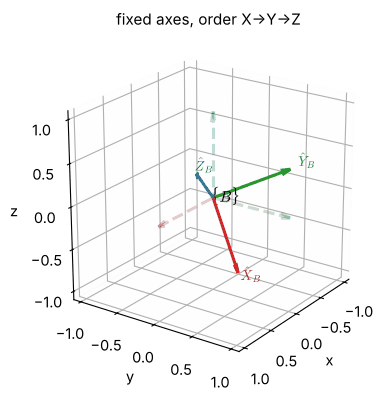

<IPython.core.display.Math object>

In [4]:
ELEM = {"X": rotx, "Y": roty, "Z": rotz}

def compose(order="XYZ", axes_type="fixed", a1=30.0, a2=45.0, a3=60.0):
    R = np.eye(3)
    for axis, ang in zip(order, (a1, a2, a3)):
        step = ELEM[axis](deg(ang))
        R = R @ step if axes_type == "current" else step @ R
    ax = new_axes3d(lim=1.1, figsize=(4.4, 4.4), title=f"{axes_type} axes, order {'→'.join(order)}")
    draw_frame(ax, np.eye(3), name="A", alpha=0.25, ls="--", label_axes=False)
    draw_frame(ax, R, name="B", length=0.9)
    plt.show()
    display(Math(matrix_to_latex(R, 4, r"{}^{A}_{B}R")))

interact(compose,
         order=widgets.Dropdown(options=["XYZ", "ZYX", "ZYZ", "XZX", "YXZ"], value="XYZ"),
         axes_type=widgets.ToggleButtons(options=["fixed", "current"], value="fixed"),
         a1=widgets.FloatSlider(30, min=-180, max=180, step=5, description="1st (°)"),
         a2=widgets.FloatSlider(45, min=-180, max=180, step=5, description="2nd (°)"),
         a3=widgets.FloatSlider(60, min=-180, max=180, step=5, description="3rd (°)"));

## 4. Rotations do not commute

The previous section has already shown that the order of two $90^\circ$ rotations matters. This is a general
fact: finite rotations about different axes **do not commute**, unlike translations. Craig's Example 2.7 makes
the point with $30^\circ$ rotations about fixed $\hat Z$ and $\hat X$, computed below. (Infinitesimal rotations
*do* commute to first order, which is why angular velocities can be added as vectors — a topic of Chapter 5.)

In [5]:
A = rotz(deg(30)) @ rotx(deg(30))
B = rotx(deg(30)) @ rotz(deg(30))
display(Math(matrix_to_latex(A, 3, r"R_Z(30^\circ)R_X(30^\circ)") + r",\quad "
             + matrix_to_latex(B, 3, r"R_X(30^\circ)R_Z(30^\circ)")))
print("Equal?", np.allclose(A, B), "   largest difference:", abs(A - B).max().round(4))
eps = 1e-4
print("Commutator of two tiny rotations (1e-4 rad):",
      abs(rotz(eps) @ rotx(eps) - rotx(eps) @ rotz(eps)).max(), " ~ eps^2")

<IPython.core.display.Math object>

Equal? False    largest difference: 0.25
Commutator of two tiny rotations (1e-4 rad): 9.999999966666668e-09  ~ eps^2


## 5. Operators: rotating and translating vectors

The same mathematics can be read differently. Instead of re-describing a fixed point in a new frame, we may
**move** a vector to a new position while staying in **one** frame. A matrix used in this way is called an
**operator** (in physics, an *active* transformation, as opposed to the *passive* mapping of Section 1).

* **Rotational operator.** $R_K(\theta)$ rotates a vector by $\theta$ about the axis $\hat K$:
  ${}^{A}P_2 = R_K(\theta)\,{}^{A}P_1$. Both vectors are written in the same frame $\{A\}$, so there are no
  subscripts on $R$.
* **Translational operator.** ${}^{A}P_2 = {}^{A}P_1 + {}^{A}Q$ moves the point by the vector $Q$.

**Craig Example 2.3.** Rotate ${}^{A}P_1 = (0,\ 2,\ 0)$ by $30^\circ$ about $\hat Z$:
${}^{A}P_2 = R_Z(30^\circ)\,{}^{A}P_1 = (-1.000,\ 1.732,\ 0)$.
These are exactly the numbers of Craig Example 2.1 (a *mapping*), yet the meaning differs: there the point
stayed put and the frame was rotated; here the frame stays put and the vector is turned. The figure compares
the two readings.

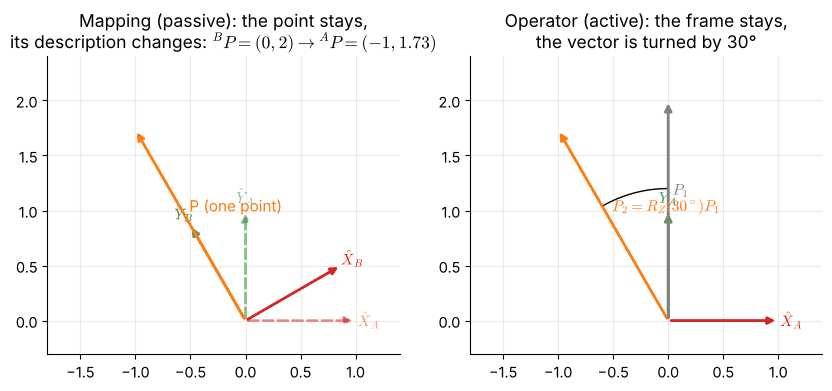

R_Z(30°) (0, 2, 0) = [-1.     1.732  0.   ]


In [6]:
P1 = np.array([0.0, 2.0])
R2 = rotz(deg(30))[:2, :2]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
# mapping: point fixed, frame {B} rotated; ^B P = (0, 2) -> ^A P = R ^B P
ax = axs[0]
draw_frame_2d(ax, 0, name="A", alpha=0.5, ls="--"); draw_frame_2d(ax, deg(30), name="B")
draw_vector_2d(ax, [0, 0], R2 @ P1, label="P (one point)")
ax.set_title("Mapping (passive): the point stays,\n" r"its description changes: ${}^{B}P=(0,2)\to{}^{A}P=(-1,1.73)$")
# operator: one frame, vector rotated
ax = axs[1]
draw_frame_2d(ax, 0, name="A")
draw_vector_2d(ax, [0, 0], P1, color="grey", label=r"$P_1$")
draw_vector_2d(ax, [0, 0], R2 @ P1, label=r"$P_2 = R_Z(30^\circ)P_1$")
ang = np.linspace(np.pi / 2, np.pi / 2 + deg(30), 20); ax.plot(1.2 * np.cos(ang), 1.2 * np.sin(ang), "k", lw=1)
ax.set_title("Operator (active): the frame stays,\nthe vector is turned by 30°")
for ax in axs:
    ax.set_xlim(-1.8, 1.4); ax.set_ylim(-0.3, 2.4); ax.set_aspect("equal"); ax.grid(alpha=0.25)
plt.show()
print("R_Z(30°) (0, 2, 0) =", (rotz(deg(30)) @ [0, 2, 0]).round(3))

## 6. Three interpretations of a rotation matrix

The same $3\times3$ orthonormal matrix serves three purposes (Craig §2.5). The leading super- and subscripts, or
their absence, tell the reader which one is meant.

| Interpretation | Formula | What happens |
|:--|:--|:--|
| **Description** of a frame | ${}^{A}_{B}R$ | its columns are the axes of $\{B\}$ written in $\{A\}$ |
| **Mapping** between frames | ${}^{A}P = {}^{A}_{B}R\,{}^{B}P$ | the point does not move; its coordinates change frame |
| **Operator** within a frame | $P_2 = R\,P_1$ | the vector is rotated; the frame does not change |

## 7. Skew-symmetric matrices and the cross product

For a vector $\boldsymbol\omega = (\omega_x,\omega_y,\omega_z)$ define the **skew-symmetric matrix**

$$
[\boldsymbol\omega]_\times = \begin{bmatrix} 0 & -\omega_z & \omega_y\\ \omega_z & 0 & -\omega_x\\ -\omega_y & \omega_x & 0\end{bmatrix},
\qquad [\boldsymbol\omega]_\times\,\mathbf p = \boldsymbol\omega\times\mathbf p,
\qquad [\boldsymbol\omega]_\times^{\mathsf T} = -[\boldsymbol\omega]_\times .
$$

It turns a cross product into a matrix product, and it appears in Rodrigues' formula (Section 2.5), in the
quaternion product, and in the relation between the rate of change of a rotation matrix and angular velocity.

> **Beyond the syllabus — angular velocity (Lynch & Park §3.2.2).** Differentiating $R^{\mathsf T}R = I$ gives
> $\dot R^{\mathsf T}R + R^{\mathsf T}\dot R = 0$, so $\dot R R^{\mathsf T}$ is skew-symmetric:
> $\dot R R^{\mathsf T} = [\boldsymbol\omega_s]_\times$, where $\boldsymbol\omega_s$ is the angular velocity written in the
> fixed frame. Similarly $R^{\mathsf T}\dot R = [\boldsymbol\omega_b]_\times$ in the body frame, and
> $\boldsymbol\omega_s = R\,\boldsymbol\omega_b$. Chapter 5 builds on this.

The cell verifies the cross-product identity and the angular-velocity relation by finite differences for a body
spinning at $\boldsymbol\omega = (0.3,\,-0.2,\,1.0)$ rad/s.

In [7]:
from rgkit.transforms import rot_axis_angle
w, p = np.array([0.3, -0.2, 1.0]), np.array([1.0, 2.0, 3.0])
print("[w]x p == w x p :", np.allclose(skew(w) @ p, np.cross(w, p)), "   [w]x^T == -[w]x :",
      np.allclose(skew(w).T, -skew(w)))

R0 = rotz(deg(20)) @ rotx(deg(40))
R_of_t = lambda t: rot_axis_angle(w, np.linalg.norm(w) * t) @ R0        # constant spin about w (fixed frame)
h = 1e-6
Rdot = (R_of_t(h) - R_of_t(-h)) / (2 * h)
w_s = np.array([(Rdot @ R0.T)[2, 1], (Rdot @ R0.T)[0, 2], (Rdot @ R0.T)[1, 0]])
print("angular velocity recovered from Rdot R^T:", w_s.round(6), " (expected", w, ")")

[w]x p == w x p : True    [w]x^T == -[w]x : True
angular velocity recovered from Rdot R^T: [ 0.3 -0.2  1. ]  (expected [ 0.3 -0.2  1. ] )


## 8. Mappings and compositions in MuJoCo

In MJCF a `<body>` nested inside another body is positioned **relative to its parent**: its `pos` attribute is
${}^{\text{parent}}P_{\text{child ORG}}$ and its orientation attribute gives ${}^{\text{parent}}_{\ \ \text{child}}R$.
MuJoCo then computes every body's pose in the world frame by — exactly — the chain rule. A `<site>` is a
massless marker attached to a body; its `pos` is the site's position written in the body frame, i.e. ${}^{B}P$,
and MuJoCo reports its world position in `data.site_xpos`, i.e. ${}^{A}P$.

The model below has a chain world $\{A\}$ → $\{B\}$ → $\{C\}$. We specify each child's orientation with the
MJCF `euler` attribute, setting the compiler to `eulerseq="xyz"` (lower-case letters denote rotations about
**current** axes — the post-multiplication rule of Section 3). We then check:

1. that MuJoCo's world orientation of $\{C\}$ equals ${}^{A}_{B}R\,{}^{B}_{C}R$ computed by hand, and
2. that the world position of a site on $\{B\}$ equals ${}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$.

world orientation of C:  MuJoCo == R_AB @ R_BC ? True
world position of C:     MuJoCo == R_AB p_BC + p_AB ? True
marker site:             MuJoCo [0.3458 0.0364 0.6924]  hand [0.3458 0.0364 0.6924]


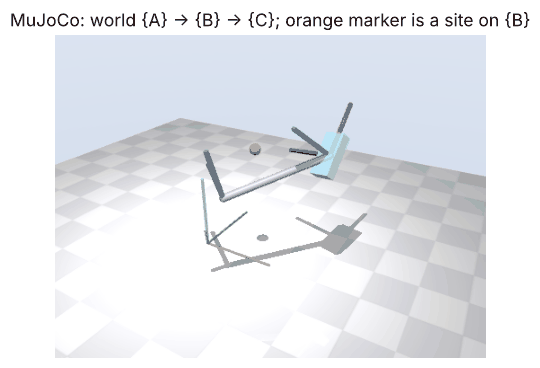

In [8]:
from rgkit import mujoco_utils as mju
import mujoco

p_AB, eul_AB = np.array([0.3, -0.2, 0.5]), (20, 0, 50)       # {B} in {A}: position, xyz-current angles (deg)
p_BC, eul_BC = np.array([0.6, 0.0, 0.0]), (0, -35, 30)       # {C} in {B}
P_B = np.array([0.25, 0.15, 0.10])                           # a marker point, written in {B}

xml = f"""
<mujoco model="chain_A_B_C">
  <compiler angle="degree" eulerseq="xyz"/>
  {mju.scene_assets()}
  <worldbody>
    {mju.floor(z=0.0)}
    {mju.frame_axes_geoms(length=0.45, radius=0.008, alpha=0.4, prefix="A_")}
    <body name="B" pos="{p_AB[0]} {p_AB[1]} {p_AB[2]}" euler="{eul_AB[0]} {eul_AB[1]} {eul_AB[2]}">
      {mju.frame_axes_geoms(length=0.3, radius=0.012, prefix="B_")}
      <geom type="capsule" fromto="0 0 0 {p_BC[0]} {p_BC[1]} {p_BC[2]}" size="0.02" rgba="0.6 0.6 0.65 1"/>
      <site name="marker" pos="{P_B[0]} {P_B[1]} {P_B[2]}" size="0.03" rgba="1 0.5 0 1"/>
      <body name="C" pos="{p_BC[0]} {p_BC[1]} {p_BC[2]}" euler="{eul_BC[0]} {eul_BC[1]} {eul_BC[2]}">
        {mju.frame_axes_geoms(length=0.3, radius=0.012, prefix="C_")}
        <geom type="box" size="0.12 0.06 0.03" rgba="0.62 0.79 0.88 0.6" contype="0" conaffinity="0"/>
      </body>
    </body>
  </worldbody>
</mujoco>"""
model, data = mju.load(xml)

xyz_current = lambda a, b, c: rotx(deg(a)) @ roty(deg(b)) @ rotz(deg(c))  # eulerseq="xyz": post-multiply
R_AB, R_BC = xyz_current(*eul_AB), xyz_current(*eul_BC)
R_AC = R_AB @ R_BC                                                       # chain rule
P_A = R_AB @ P_B + p_AB                                                  # general mapping

print("world orientation of C:  MuJoCo == R_AB @ R_BC ?",
      np.allclose(data.body("C").xmat.reshape(3, 3), R_AC, atol=1e-9))
print("world position of C:     MuJoCo == R_AB p_BC + p_AB ?",
      np.allclose(data.body("C").xpos, R_AB @ p_BC + p_AB, atol=1e-9))
print("marker site:             MuJoCo", data.site("marker").xpos.round(6), " hand", P_A.round(6))
img = mju.render(model, data, camera=dict(azimuth=120, elevation=-28, distance=2.2, lookat=(0.4, 0.1, 0.4)))
plt.figure(figsize=(5.6, 4.2)); plt.imshow(img); plt.axis("off")
plt.title("MuJoCo: world {A} → {B} → {C}; orange marker is a site on {B}"); plt.show()

All three checks agree to machine precision. Try changing `eulerseq="xyz"` to `eulerseq="XYZ"` (upper case:
**fixed** axes). The hand calculation must then pre-multiply, `rotz(c) @ roty(b) @ rotx(a)`, to match.

## 9. Worked examples

**Example 2.2.1 (Craig Example 2.1 — mapping with a rotated frame).** $\{B\}$ is rotated $30^\circ$ about
$\hat Z$ relative to $\{A\}$, and ${}^{B}P = (0,\ 2,\ 0)$. Find ${}^{A}P$.

*Solution.* ${}^{A}P = R_Z(30^\circ)\,{}^{B}P = (0.866\cdot0 - 0.5\cdot2,\ 0.5\cdot0 + 0.866\cdot2,\ 0) = (-1.000,\ 1.732,\ 0)$.
Check: the point lies two units along $\hat Y_B$, which points $30^\circ$ to the left of $\hat Y_A$, so ${}^{A}P$
must have a negative $x$ component and length 2: $\sqrt{1+1.732^2} = 2$. ✓

**Example 2.2.2 (Craig Example 2.2 — general mapping).** $\{B\}$ is rotated $30^\circ$ about $\hat Z_A$ and its
origin is at ${}^{A}P_{BORG} = (10,\ 5,\ 0)$. Find ${}^{A}P$ for ${}^{B}P = (3,\ 7,\ 0)$.

*Solution.* ${}^{A}_{B}R\,{}^{B}P = (0.866\cdot3 - 0.5\cdot7,\ 0.5\cdot3 + 0.866\cdot7,\ 0) = (-0.902,\ 7.562,\ 0)$, so
${}^{A}P = (9.098,\ 12.562,\ 0)$.

**Example 2.2.3 — mixed fixed and current rotations.** Starting from $R = I$, a body is rotated $30^\circ$ about
its current $X$, then $45^\circ$ about its current $Z$, then $60^\circ$ about the **fixed** $Y$. Find $R$.

*Solution.* The first two steps post-multiply: $R_X(30^\circ)R_Z(45^\circ)$. The last pre-multiplies:

$$
R = R_Y(60^\circ)\,\big[R_X(30^\circ)\,R_Z(45^\circ)\big] =
\begin{bmatrix} 0.6597 & -0.0474 & 0.7500\\ 0.6124 & 0.6124 & -0.5000\\ -0.4356 & 0.7891 & 0.4330\end{bmatrix}.
$$

**Example 2.2.4 — finding a rotation from a mapping.** A frame $\{B\}$ shares its origin with $\{A\}$. Three
points have ${}^{B}P = \hat X, \hat Y, \hat Z$ and are measured in $\{A\}$ at $(0,0,1)$, $(-1,0,0)$, $(0,-1,0)$.
Find ${}^{A}_{B}R$.

*Solution.* ${}^{A}_{B}R\,\hat X$ is the first column of the matrix, and so on. Hence
${}^{A}_{B}R = \begin{bmatrix}0&-1&0\\0&0&-1\\1&0&0\end{bmatrix}$, which is $R_X(90^\circ)R_Z(90^\circ)$ — the
"current axes" result of Section 3. Its determinant is $+1$.

In [9]:
print("Ex 2.2.1:", (rotz(deg(30)) @ [0, 2, 0]).round(3))
print("Ex 2.2.2:", (rotz(deg(30)) @ [3, 7, 0] + [10, 5, 0]).round(3))
R = roty(deg(60)) @ (rotx(deg(30)) @ rotz(deg(45)))
print("Ex 2.2.3:\n", R.round(4))
M = np.column_stack([[0, 0, 1], [-1, 0, 0], [0, -1, 0]])
print("Ex 2.2.4: equals Rx(90) Rz(90)?", np.allclose(M, rotx(deg(90)) @ rotz(deg(90))),
      "  rotation?", is_rotation(M))

Ex 2.2.1: [-1.     1.732  0.   ]
Ex 2.2.2: [ 9.098 12.562  0.   ]
Ex 2.2.3:
 [[ 0.6597 -0.0474  0.75  ]
 [ 0.6124  0.6124 -0.5   ]
 [-0.4356  0.7891  0.433 ]]
Ex 2.2.4: equals Rx(90) Rz(90)? True   rotation? True


## 10. Summary

| Result | Formula |
|:--|:--|
| Translated frames | ${}^{A}P = {}^{B}P + {}^{A}P_{BORG}$ |
| Rotated frames | ${}^{A}P = {}^{A}_{B}R\,{}^{B}P$ |
| General mapping | ${}^{A}P = {}^{A}_{B}R\,{}^{B}P + {}^{A}P_{BORG}$ |
| Chain rule | ${}^{A}_{C}R = {}^{A}_{B}R\,{}^{B}_{C}R$ |
| Current-axes step | $R \leftarrow R\,R_{\text{step}}$ (post-multiply) |
| Fixed-axes step | $R \leftarrow R_{\text{step}}\,R$ (pre-multiply) |
| Operator | $P_2 = R_K(\theta)\,P_1$ (same frame) |
| Cross product | $\boldsymbol\omega\times\mathbf p = [\boldsymbol\omega]_\times\mathbf p$ |

### Common mistakes

* Adding vectors written in frames of **different orientation** (e.g. ${}^{B}P + {}^{A}P_{BORG}$ when $\{B\}$ is rotated).
* Multiplying on the **wrong side**: always ask "about the fixed axes, or the current ones?"
* Writing ${}^{A}_{B}R\,{}^{C}P$ — the inner indices do not match, so the expression is meaningless.
* Treating the same numbers in a mapping and an operator as the same *physical* situation.

## Exercises

**2.2.1** $\{B\}$ is rotated $90^\circ$ about $\hat Z_A$ and its origin is at ${}^{A}P_{BORG} = (1, 2, 0)$.
(a) Find ${}^{A}P$ for ${}^{B}P = (1, 0, 0)$. (b) Find ${}^{B}P$ for ${}^{A}P = (1, 3, 0)$.

<details><summary>Answer</summary>

(a) $R_Z(90^\circ)(1,0,0) + (1,2,0) = (0,1,0)+(1,2,0) = (1,3,0)$.
(b) ${}^{B}P = R^{\mathsf T}({}^{A}P - {}^{A}P_{BORG}) = R_Z(-90^\circ)(0,1,0) = (1,0,0)$ — consistent with (a).
</details>

**2.2.2** Show that $R_X(\alpha)R_X(\beta) = R_X(\alpha+\beta)$, so rotations about the *same* axis do commute.

<details><summary>Answer</summary>

Multiply out and use $\cos\alpha\cos\beta - \sin\alpha\sin\beta = \cos(\alpha+\beta)$ and
$\sin\alpha\cos\beta + \cos\alpha\sin\beta = \sin(\alpha+\beta)$.
</details>

**2.2.3** A body is rotated $90^\circ$ about the fixed $\hat Y$, then $90^\circ$ about the fixed $\hat Z$. Where
does its $\hat X$ axis point? Repeat with current axes.

<details><summary>Answer</summary>

Fixed: $R = R_Z(90^\circ)R_Y(90^\circ)$, first column $(0,0,-1)$: $\hat X_B$ points down. Current:
$R = R_Y(90^\circ)R_Z(90^\circ)$, first column $(0,1,0)$: $\hat X_B$ points along world $+Y$.
</details>

**2.2.4** Prove that $R[\boldsymbol\omega]_\times R^{\mathsf T} = [R\boldsymbol\omega]_\times$ for any rotation $R$.
(*Hint:* apply both sides to an arbitrary vector and use the fact that rotations preserve cross products.)

<details><summary>Answer</summary>

$R[\boldsymbol\omega]_\times R^{\mathsf T}\mathbf p = R(\boldsymbol\omega\times R^{\mathsf T}\mathbf p) = (R\boldsymbol\omega)\times(RR^{\mathsf T}\mathbf p) = (R\boldsymbol\omega)\times\mathbf p$.
</details>

**2.2.5** (*MuJoCo*) In the model of Section 8 change the compiler to `eulerseq="XYZ"`. Which line of the
hand calculation must change for the checks to pass again? Make the change and confirm.

<details><summary>Answer</summary>

`xyz_current` must become a fixed-axes product: `lambda a, b, c: rotz(deg(c)) @ roty(deg(b)) @ rotx(deg(a))`.
</details>

## Further reading and lectures

* Craig §2.3–2.5; Lynch & Park §3.2.1 and §3.2.2; Spong et al. Ch. 2; Siciliano et al. §2.2–2.3.
* Video: [Prof. G. C. Nandi, Lecture 7 — Basics of rotational transformation](https://www.youtube.com/watch?v=588iwEM-Dto); [Prof. G. C. Nandi, Lecture 15 — Spatial transformation explained in a simple way](https://www.youtube.com/watch?v=CJdCTyDpX4U); [ThatsEngineering — Spatial descriptions and transformation matrices](https://www.youtube.com/watch?v=4Y1_y9DI_Hw); [ThatsEngineering — Spatial descriptions — worked example](https://www.youtube.com/watch?v=r244ADkuexk); [Modern Robotics 3.2.1 Rotation matrices (part 2)](https://www.youtube.com/watch?v=6KIPusOv5fA); [Modern Robotics 3.2.2 Angular velocities](https://www.youtube.com/watch?v=zJJldJYMxVU).
* MuJoCo documentation: [MJCF `compiler/eulerseq`](https://mujoco.readthedocs.io/en/stable/XMLreference.html#compiler).

---

[← 2.1 Positions, Orientations and Frames](2.1-positions-orientations-and-frames.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [2.3 Homogeneous Transformations →](2.3-homogeneous-transformations.ipynb)